# 04 · Especialização por LoRA (QLoRA) e configuração C
**O que o LoRA ensina:** seguir o contrato JSON, usar só os trechos, citar o `chunk_id` certo e recusar quando o contexto não responde. **Não** decora fatos (os fatos vêm da busca).

**Dados de treino:** sintéticos, gerados pelo próprio Qwen a partir de trechos da base — (i) perguntas respondíveis, (ii) negativos difíceis (mesmo assunto, resposta ausente) e (iii) perguntas fora do domínio. Trechos usados no gabarito são **excluídos** do treino e nenhuma pergunta do teste aparece nele (`check_leakage`).

Hiperparâmetros (em `src/config.py`): QLoRA 4-bit nf4, r=16, α=32, dropout 0,05, todos os projetores de atenção+MLP, 2 épocas, lr 2e-4, batch efetivo 8.

> Requer GPU (Colab T4 serve). Tempo típico: 20–40 min de treino.

In [1]:
# --- Ambiente: funciona no Colab (via VSCode ou navegador) e localmente ---------------
import os, sys, subprocess
from pathlib import Path

REPO_URL = ""   # opcional: URL do repositório GitHub, se o projeto ainda não estiver na máquina do Colab

try:
    os.getcwd()
except FileNotFoundError:      # a pasta atual do kernel foi apagada/recriada: volta para um lugar válido
    os.chdir("/content" if Path("/content").exists() else str(Path.home()))

def achar_raiz():
    cwd = Path.cwd()
    cands = [cwd, *cwd.parents, Path("/content/GS2-GENIA"), Path("/content/drive/MyDrive/GS2-GENIA"),
             Path("/content/drive/MyDrive/GEN-IA/GS2-GENIA"), Path("/content/drive/MyDrive/GEN-IA")]
    for c in cands:
        if (c / "src" / "config.py").exists():
            return c
    for base in (Path("/content"), Path("/content/drive/MyDrive")):   # busca 1-2 níveis abaixo
        if base.exists():
            for f in list(base.glob("*/src/config.py")) + list(base.glob("*/*/src/config.py")):
                return f.parent.parent
    return None

ROOT = achar_raiz()
if ROOT is None and REPO_URL:
    subprocess.run(["git", "clone", REPO_URL, "/content/GS2-GENIA"], check=True)
    ROOT = Path("/content/GS2-GENIA")
assert ROOT is not None, "Não achei src/config.py: abra o notebook dentro da pasta GS2-GENIA ou preencha REPO_URL."
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("ROOT =", ROOT)

ROOT = /content/drive/MyDrive/GS2-GENIA


In [2]:
%pip install -q -r requirements.txt

In [3]:
import json, gc, torch, pandas as pd, matplotlib.pyplot as plt
from src import config
from src.ingest import load_chunks
from src.evaluate import load_testset, run_config, aggregate
from src.rag import Generator, answer
from src.retrieval import Retriever, load_threshold
from src import train_lora

chunks = load_chunks(); by_id = {c["chunk_id"]: c for c in chunks}
retriever = Retriever(chunks)
items = load_testset()
TH = load_threshold()
gen = None
if config.TRAIN_PATH.exists():     # já gerado antes: reaproveita (apague o arquivo para regenerar, ~18 min)
    rows = [json.loads(l) for l in open(config.TRAIN_PATH, encoding="utf-8") if l.strip()]
    print(f"Reutilizando {len(rows)} exemplos de {config.TRAIN_PATH}")
else:
    gen = Generator()
    rows = train_lora.build_train_set(gen, retriever, chunks, items)
leaks = train_lora.check_leakage(rows, items)
print("Vazamento teste->treino:", leaks or "nenhum")
assert not leaks

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

Reutilizando 330 exemplos de /content/drive/MyDrive/GS2-GENIA/data/train_lora.jsonl
Vazamento teste->treino: nenhum


### Revisão manual de amostra (obrigatória)
Os rótulos `hardneg` ("não consta") foram gerados automaticamente: uma pergunta "difícil" pode, na verdade, ser respondível pelo contexto. Confira a amostra; remova exemplos duvidosos de `data/train_lora.jsonl` antes de treinar.

In [4]:
import random
amostra = random.Random(0).sample([r for r in rows if r["tipo"] == "hardneg"], min(8, sum(r["tipo"] == "hardneg" for r in rows)))
for r in amostra:
    print("-", r["pergunta"])
print()
print(pd.Series([r["tipo"] for r in rows]).value_counts())

- Qual é a importância dos mapas de espacialização das ocorrências para a determinação das áreas com maior risco de incêndios?
- Qual é o objetivo principal da Política de Gestão Compartilhada e Responsável do Fogo no Brasil?
- Qual é a capacidade máxima de passageiros em um helicóptero utilizado como recurso único?
- Quem pode ser responsável pela análise de segurança do PAI?
- Qual é a função específica do Chefe na estrutura do SCI?
- Quem é responsável por definir as diretrizes de emprego dos recursos?
- Qual é a principal função do briefing durante a gestão de um incidente?
- Qual é o impacto da umidade relativa do ar no tempo de preaquecimento do combustível morto?

ok         250
hardneg     50
ood         30
Name: count, dtype: int64


In [5]:
!grep -n "warmup" /content/drive/MyDrive/GS2-GENIA/src/train_lora.py

206:    # aquecimento de 5% dos passos, em PASSOS (o argumento warmup_ratio foi removido
207:    # nas versões novas do transformers; warmup_steps funciona em todas)
209:    warmup = max(1, int(0.05 * passos_por_epoca * config.TRAIN_EPOCHS))
214:        learning_rate=config.TRAIN_LR, lr_scheduler_type="cosine", warmup_steps=warmup,


330/330 exemplos cabem em 2048 tokens


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


Step,Training Loss
10,0.313266
20,0.205787
30,0.189652
40,0.149402
50,0.118103
60,0.096023
70,0.077100
80,0.088593


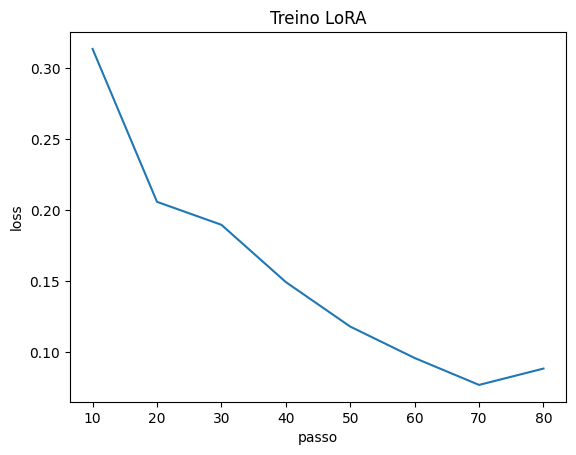

In [6]:
gen = None; gc.collect(); torch.cuda.empty_cache()
log = train_lora.train()
loss = [(h["step"], h["loss"]) for h in log if "loss" in h]
plt.plot(*zip(*loss)); plt.xlabel("passo"); plt.ylabel("loss"); plt.title("Treino LoRA")
(ROOT / "avaliacao").mkdir(exist_ok=True); plt.savefig(ROOT / "avaliacao" / "loss_lora.png", dpi=120); plt.show()
gc.collect(); torch.cuda.empty_cache()

## Configuração C = RAG + LoRA (mesmo retriever, mesmo limiar, mesmos prompts de B)

In [16]:
!ls -la /content/drive/MyDrive/GS2-GENIA/adapters/qwen25-3b-defesa-civil/

total 128167
drwx------ 2 root root      4096 Nov 16 01:13 .
drwx------ 4 root root      4096 Nov 16 01:13 ..
-rw------- 1 root root      1180 Nov 16 01:13 adapter_config.json
-rw------- 1 root root 119801528 Nov 16 01:13 adapter_model.safetensors
-rw------- 1 root root      2507 Nov 16 01:13 chat_template.jinja
-rw------- 1 root root      5202 Nov 16 01:13 README.md
-rw------- 1 root root       694 Nov 16 01:13 tokenizer_config.json
-rw------- 1 root root  11421892 Nov 16 01:13 tokenizer.json


In [17]:
import gc, torch
gc.collect(); torch.cuda.empty_cache()
try:
    from peft import PeftModel
    print("peft ok")
except Exception as e:
    print(type(e).__name__, ":", str(e)[:1500])

peft ok


In [18]:
%pip uninstall -y torchao

Found existing installation: torchao 0.18.0
Uninstalling torchao-0.18.0:
  Successfully uninstalled torchao-0.18.0


In [19]:
%pip install -U "torchao>=0.16.0"

  Using cached torchao-0.18.0-cp310-abi3-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (21 kB)
Using cached torchao-0.18.0-cp310-abi3-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (3.4 MB)


In [ ]:
import gc, torch, traceback
for v in ("genC", "gen"):
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()

from transformers import AutoModelForCausalLM
from peft import PeftModel
from src import config

base = AutoModelForCausalLM.from_pretrained(config.MODEL_NAME, torch_dtype=torch.float16, device_map="auto")
try:
    PeftModel.from_pretrained(base, str(config.ADAPTER_DIR))
    print("adaptador carregou OK")
except Exception:
    print(traceback.format_exc()[-1800:])

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

adaptador carregou OK


In [21]:
genC = Generator(adapter_path=config.ADAPTER_DIR)
rows_C = run_config("C_rag_lora", items, lambda q: answer(q, genC, retriever, mode="rag", threshold=TH, chunks_by_id=by_id))
for sp in ("dev", "teste"):
    print("C", sp, aggregate([r for r in rows_C if r["split"] == sp]))

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

C_rag_lora:   0%|          | 0/40 [00:00<?, ?it/s]

C dev {'n': 20, 'acuracia_%': 60.0, 'acerto_respondiveis_%': 42.9, 'recusa_correta_%': 100.0, 'alucinacao_%': 35.0, 'recusa_indevida_%': 7.1, 'json_valido_%': 100.0, 'citacao_correta_%': 69.2}
C teste {'n': 20, 'acuracia_%': 55.0, 'acerto_respondiveis_%': 35.7, 'recusa_correta_%': 100.0, 'alucinacao_%': 40.0, 'recusa_indevida_%': 7.1, 'json_valido_%': 100.0, 'citacao_correta_%': 53.8}


> O adaptador (`adapters/…`) pode passar de 100 MB e **não deve ir ao GitHub** (limite de arquivo). Está no `.gitignore`; para entregar, publique-o no Google Drive/Hugging Face e coloque o link no README, ou rode o notebook para regenerá-lo.

In [23]:
for r in rows_C:
    if r["split"] == "teste" and not r["deve_recusar"] and not r["correta"]:
        it = its[r["id"]]
        falt = [g[0] for g in it["fatos_chave"] if not any(norm(a) in norm(r["resposta"]) for a in g)]
        print(r["id"], r["status"], "gated=", r["gated"], "score=", round(r["top_score"], 3),
              "| citou", r["citacoes"], "| faltou", falt)

Q05 ok gated= False score= 0.897 | citou ['DOC002-p030-c080'] | faltou ['objetivos', 'legislac', 'parcerias']
Q08 ok gated= False score= 0.908 | citou ['DOC003-p016-c016'] | faltou ['diretrizes']
Q10 ok gated= False score= 0.838 | citou ['DOC005-p077-c148'] | faltou ['sistema nacional de informacoes sobre fogo', 'base de dados', 'areas queimadas']
Q16 ok gated= False score= 0.895 | citou ['DOC005-p071-c139'] | faltou ['hierarqu', 'estrategias', 'treinamentos']
Q18 ok gated= False score= 0.909 | citou ['DOC008-p111-c188'] | faltou ['seguranca']
Q19 ok gated= False score= 0.888 | citou ['DOC008-p030-c057'] | faltou ['expande', 'contrai', 'complexidade']
Q24 ok gated= False score= 0.881 | citou ['DOC006-p012-c019'] | faltou ['california', 'coordenacao', '1972']
Q26 ok gated= False score= 0.901 | citou ['DOC009-p003-c009'] | faltou ['analise', 'primeiros socorros', 'combate']
Q28 nao_consta gated= False score= 0.88 | citou [] | faltou ['um ano', 'revis', 'alteracao']


In [24]:
!ls -la results/

total 150
drwx------  2 root root  4096 Nov 16 01:34 .
drwx------ 12 root root  4096 Nov 16 01:04 ..
-rw-------  1 root root 44947 Nov 16 00:11 A_base.jsonl
-rw-------  1 root root 51725 Nov 16 00:14 B_rag.jsonl
-rw-------  1 root root 45399 Nov 16 01:34 C_rag_lora.jsonl
-rw-------  1 root root   423 Nov 16 00:00 threshold.json
-rw-------  1 root root  1494 Nov 16 01:13 train_log.json
